# NYC Airbnb Listings: Data Cleaning and Exploratory Analysis

- **Name:** Fouad Kouidmir
- **Dataset:** New York City Airbnb Open Data (`AB_NYC_2019.csv`), available on [Kaggle](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data)

This project builds a reproducible Python workflow that loads the 2019 New York City Airbnb listings, cleans documented data-quality problems with reusable functions, and explores how nightly prices differ by borough and room type. It combines cleaning and analysis functions, three labeled visualizations, and a written interpretation of the results. The notebook is designed to run from top to bottom so that it can serve as a foundation for later machine learning work.

## 1. Setup

Import the libraries and print their versions so that the results can be tied to the environment described in `requirements.txt`.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_PATH = "AB_NYC_2019.csv"

sns.set_theme(style="whitegrid")
print(f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

pandas 3.1.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Data Ingestion

Load the CSV file with pandas and display the first rows. The raw table is kept in `df` and is never modified; every cleaning step below returns a new copy.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 48,895 | Columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


### Data quality audit

Before cleaning, count how many rows are affected by each problem that could distort the analysis. The cleaning functions in the next section are chosen from these counts.

In [3]:
def audit_data_quality(data):
    """Counts the rows affected by each data-quality problem checked in this project.

    The result lets the issues be compared before and after cleaning. The input
    data is not modified.

    Args:
        data (pandas.DataFrame): Listings with the columns ``id``, ``price``,
            ``minimum_nights``, ``availability_365``, ``name``, ``host_name``,
            ``last_review``, ``reviews_per_month``, and ``number_of_reviews``.

    Returns:
        pandas.DataFrame: A one-column DataFrame named ``rows_affected`` with one
        row per problem checked.
    """
    names = data["name"].dropna()
    checks = {
        "Duplicate listing ids": data["id"].duplicated().sum(),
        "Price of zero or less": data["price"].le(0).sum(),
        "Minimum nights of zero or less": data["minimum_nights"].le(0).sum(),
        "Availability outside 0-365 days": (~data["availability_365"].between(0, 365)).sum(),
        "Missing listing name": data["name"].isna().sum(),
        "Missing host name": data["host_name"].isna().sum(),
        "Listing name with extra spaces": names.ne(names.str.strip()).sum(),
        "Missing last_review date": data["last_review"].isna().sum(),
        "Missing reviews_per_month": data["reviews_per_month"].isna().sum(),
        "Missing reviews_per_month but reviews exist": (
            data["reviews_per_month"].isna() & data["number_of_reviews"].gt(0)
        ).sum(),
    }
    return pd.Series(checks, name="rows_affected").to_frame()


audit_data_quality(df)

,rows_affected
Duplicate listing ids,0
Price of zero or less,11
Minimum nights of zero or less,0
Availability outside 0-365 days,0
Missing listing name,16
Missing host name,21
Listing name with extra spaces,238
Missing last_review date,10052
Missing reviews_per_month,10052
Missing reviews_per_month but reviews exist,0


## 3. Data Cleaning

Each function below addresses one problem found in the audit and returns a new DataFrame:

| Function | Problem it addresses | Why it matters |
| --- | --- | --- |
| `remove_invalid_listings` | 11 listings with a price of 0, plus validation checks for duplicate ids, non-positive minimum nights, and impossible availability | A price of 0 is not a real nightly rate and would pull down every average price. The other checks found no problems but guard against bad data in future versions of the file. |
| `clean_text_columns` | 238 listing names with extra spaces and 16 and 21 missing listing and host names | Extra spaces break grouping and matching, and missing text would silently drop rows from text operations. |
| `clean_review_data` | 10,052 missing `reviews_per_month` and `last_review` values | All of these listings have zero reviews, so a monthly rate of 0 is accurate, while a review date cannot be invented and stays missing. |

In [4]:
TEXT_COLUMNS = ["name", "host_name"]


def remove_invalid_listings(data):
    """Drops duplicate listings and rows with impossible numeric values.

    Removes repeated ``id`` values, prices and minimum stays of zero or less,
    and availability outside the 0-365 day range.

    Args:
        data (pandas.DataFrame): Raw listings with the columns ``id``, ``price``,
            ``minimum_nights``, and ``availability_365``.

    Returns:
        pandas.DataFrame: A new DataFrame without the invalid rows and with a reset
        index. The input is not modified.
    """
    unique = data.drop_duplicates(subset="id")
    valid = (
        unique["price"].gt(0)
        & unique["minimum_nights"].gt(0)
        & unique["availability_365"].between(0, 365)
    )
    return unique.loc[valid].reset_index(drop=True)


def clean_text_columns(data):
    """Strips extra spaces from text columns and labels missing text as 'Unknown'.

    Applies to the columns in ``TEXT_COLUMNS``. Blank strings are treated as
    missing.

    Args:
        data (pandas.DataFrame): Listings containing every column in
            ``TEXT_COLUMNS``.

    Returns:
        pandas.DataFrame: A new DataFrame with trimmed text and no missing values
        in the text columns. The input is not modified.
    """
    cleaned = data.copy()
    for column in TEXT_COLUMNS:
        stripped = cleaned[column].str.strip()
        cleaned[column] = stripped.mask(stripped.eq("")).fillna("Unknown")
    return cleaned


def clean_review_data(data):
    """Converts review dates and fills the review rate for listings with no reviews.

    ``last_review`` becomes a datetime column. ``reviews_per_month`` is set to 0
    only where it is missing and ``number_of_reviews`` is 0; missing review
    dates are left missing because no date exists.

    Args:
        data (pandas.DataFrame): Listings with the columns ``last_review``,
            ``reviews_per_month``, and ``number_of_reviews``.

    Returns:
        pandas.DataFrame: A new DataFrame with the converted and filled review
        columns. The input is not modified.
    """
    cleaned = data.copy()
    cleaned["last_review"] = pd.to_datetime(cleaned["last_review"], errors="coerce")
    unreviewed = cleaned["reviews_per_month"].isna() & cleaned["number_of_reviews"].eq(0)
    cleaned.loc[unreviewed, "reviews_per_month"] = 0.0
    return cleaned


def summarize_cleaning(raw, cleaned):
    """Compares row and missing-value counts before and after cleaning.

    Args:
        raw (pandas.DataFrame): The listings before cleaning.
        cleaned (pandas.DataFrame): The listings after cleaning.

    Returns:
        pandas.DataFrame: A table with the columns ``before`` and ``after`` that
        shows the number of rows and the missing values in ``name``, ``host_name``,
        ``reviews_per_month``, and ``last_review``.
    """
    columns = ["name", "host_name", "reviews_per_month", "last_review"]
    before = pd.Series({"Rows": len(raw), **{f"Missing {c}": raw[c].isna().sum() for c in columns}})
    after = pd.Series({"Rows": len(cleaned), **{f"Missing {c}": cleaned[c].isna().sum() for c in columns}})
    return pd.DataFrame({"before": before, "after": after})

Apply the three cleaning functions in order, then confirm with assertions that the cleaned data meets the rules the analysis depends on.

In [5]:
cleaned_df = (
    df.pipe(remove_invalid_listings)
    .pipe(clean_text_columns)
    .pipe(clean_review_data)
)

assert cleaned_df["id"].is_unique
assert cleaned_df["price"].gt(0).all()
assert cleaned_df["reviews_per_month"].notna().all()
assert cleaned_df[["name", "host_name"]].notna().all().all()

print(f"Cleaning removed {len(df) - len(cleaned_df)} rows; {len(cleaned_df):,} listings remain.")
display(summarize_cleaning(df, cleaned_df))
cleaned_df.head()

Cleaning removed 11 rows; 48,884 listings remain.


,before,after
Rows,48895,48884
Missing name,16,0
Missing host_name,21,0
Missing reviews_per_month,10052,0
Missing last_review,10052,10051


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaT,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 4. Exploratory Data Analysis

The `exploratory_analysis` function bundles the main descriptive views used in this project: summary statistics, grouped views by borough and room type, a filtered view of high-priced neighbourhoods, and a correlation matrix. Identifier and coordinate columns (`id`, `host_id`, `latitude`, `longitude`) are left out of the statistics and correlations because their numeric values have no quantitative meaning. Neighbourhoods need at least 100 listings to appear in the filtered view so that tiny samples do not dominate the ranking.

In [6]:
ANALYSIS_COLUMNS = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
]

GROUP_METRICS = {
    "listings": ("id", "count"),
    "average_price": ("price", "mean"),
    "median_price": ("price", "median"),
    "average_reviews": ("number_of_reviews", "mean"),
    "average_availability": ("availability_365", "mean"),
}


def exploratory_analysis(data, min_listings=100, top_n=5):
    """Summarizes cleaned listings with statistics, grouped views, and correlations.

    Args:
        data (pandas.DataFrame): Cleaned listings that include the columns in
            ``ANALYSIS_COLUMNS`` plus ``id``, ``neighbourhood_group``,
            ``neighbourhood``, and ``room_type``.
        min_listings (int): Minimum number of listings a neighbourhood needs to be
            ranked in ``expensive_neighbourhoods``. Defaults to 100.
        top_n (int): Number of neighbourhoods to keep in
            ``expensive_neighbourhoods``. Defaults to 5.

    Returns:
        dict[str, pandas.DataFrame]: A dictionary with these keys:

        * ``summary_statistics``: ``describe()`` of the numeric analysis columns.
        * ``borough_summary``: Grouped metrics by borough, sorted by average price.
        * ``room_type_summary``: Grouped metrics by room type, sorted by average
          price.
        * ``expensive_neighbourhoods``: The ``top_n`` neighbourhoods with at least
          ``min_listings`` listings, ranked by median price.
        * ``correlations``: Pearson correlations between the analysis columns.
    """
    borough_summary = (
        data.groupby("neighbourhood_group")
        .agg(**GROUP_METRICS)
        .sort_values("average_price", ascending=False)
    )
    room_type_summary = (
        data.groupby("room_type")
        .agg(**GROUP_METRICS)
        .sort_values("average_price", ascending=False)
    )
    expensive_neighbourhoods = (
        data.groupby(["neighbourhood_group", "neighbourhood"])
        .agg(**GROUP_METRICS)
        .query("listings >= @min_listings")
        .nlargest(top_n, "median_price")
    )
    return {
        "summary_statistics": data[ANALYSIS_COLUMNS].describe().T,
        "borough_summary": borough_summary,
        "room_type_summary": room_type_summary,
        "expensive_neighbourhoods": expensive_neighbourhoods,
        "correlations": data[ANALYSIS_COLUMNS].corr(),
    }

Run the function on the cleaned data and review each output.

In [7]:
eda_results = exploratory_analysis(cleaned_df)

for name, table in eda_results.items():
    print(name.replace("_", " ").title())
    display(table.round(2))

Summary Statistics


,count,mean,std,min,25%,50%,75%,max
price,48884.0,152.76,240.17,10.0,69.00,106.00,175.00,10000.0
minimum_nights,48884.0,7.03,20.51,1.0,1.00,3.00,5.00,1250.0
number_of_reviews,48884.0,23.27,44.55,0.0,1.00,5.00,24.00,629.0
reviews_per_month,48884.0,1.09,1.60,0.0,0.04,0.37,1.58,58.5
calculated_host_listings_count,48884.0,7.14,32.96,1.0,1.00,1.00,2.00,327.0
availability_365,48884.0,112.78,131.63,0.0,0.00,45.00,227.00,365.0


Borough Summary


,listings,average_price,median_price,average_reviews,average_availability
neighbourhood_group,,,,,
Manhattan,21660,196.88,150.0,20.99,111.98
Brooklyn,20095,124.44,90.0,24.20,100.22
Staten Island,373,114.81,75.0,30.94,199.68
Queens,5666,99.52,75.0,27.70,144.45
Bronx,1090,87.58,65.0,25.98,165.79


Room Type Summary


,listings,average_price,median_price,average_reviews,average_availability
room_type,,,,,
Entire home/apt,25407,211.81,160.0,22.84,111.93
Private room,22319,89.81,70.0,24.10,111.20
Shared room,1158,70.25,45.0,16.62,161.87


Expensive Neighbourhoods


listings  average_price  median_price  \
neighbourhood_group neighbourhood                                               
Manhattan           Tribeca                  177         490.64         295.0   
                    Midtown                 1545         282.72         210.0   
                    Financial District       744         225.49         200.0   
                    West Village             768         267.68         200.0   
                    Chelsea                 1113         249.74         199.0   

                                        average_reviews  average_availability  
neighbourhood_group neighbourhood                                              
Manhattan           Tribeca                       11.49                126.51  
                    Midtown                       12.59                157.70  
                    Financial District             9.32                191.54  
                    West Village                  19.38                 85.46  
                    Chelsea                       21.24                114.00

Correlations


,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
price,1.00,0.04,-0.05,-0.05,0.06,0.08
minimum_nights,0.04,1.00,-0.08,-0.12,0.13,0.14
number_of_reviews,-0.05,-0.08,1.00,0.59,-0.07,0.17
reviews_per_month,-0.05,-0.12,0.59,1.00,-0.05,0.16
calculated_host_listings_count,0.06,0.13,-0.07,-0.05,1.00,0.23
availability_365,0.08,0.14,0.17,0.16,0.23,1.00


## 5. Visualizations

Three figures answer three questions: how nightly prices are distributed, how they differ by borough, and how they differ by room type. Prices are extremely right-skewed (the maximum is $10,000), so Figures 1 and 3 show listings up to the 99th percentile of price to keep the typical range readable. All listings stay in the cleaned data and in the borough averages shown in Figure 2.

In [8]:
price_cap = cleaned_df["price"].quantile(0.99)
plot_df = cleaned_df.loc[cleaned_df["price"] <= price_cap]
excluded = len(cleaned_df) - len(plot_df)
print(f"Figures 1 and 3 show prices up to ${price_cap:,.0f}; {excluded} higher-priced listings are not drawn.")

Figures 1 and 3 show prices up to $799; 474 higher-priced listings are not drawn.


### Figure 1: Distribution of nightly prices

A histogram shows the overall shape of the price distribution, and the mean and median lines show how much a small number of expensive listings pull the average upward.

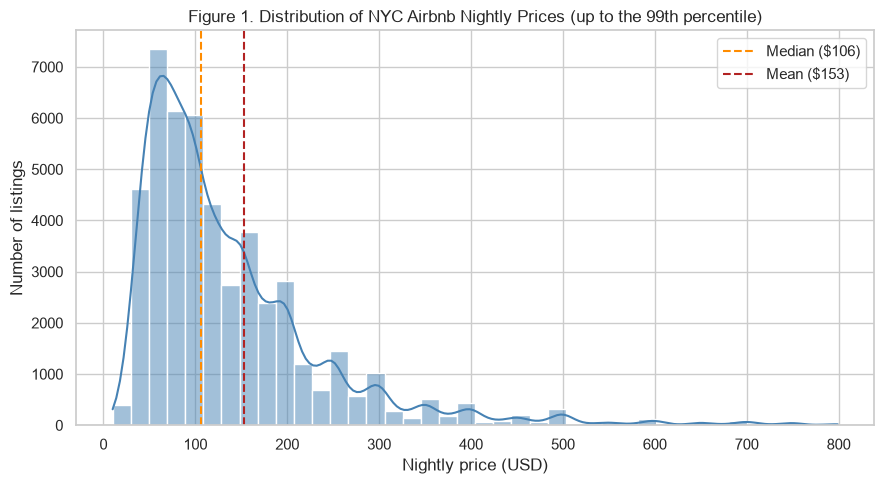

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(plot_df["price"], bins=40, kde=True, color="steelblue", ax=ax)
ax.axvline(cleaned_df["price"].median(), color="darkorange", linestyle="--",
           label=f"Median (${cleaned_df['price'].median():,.0f})")
ax.axvline(cleaned_df["price"].mean(), color="firebrick", linestyle="--",
           label=f"Mean (${cleaned_df['price'].mean():,.0f})")
ax.set_title("Figure 1. Distribution of NYC Airbnb Nightly Prices (up to the 99th percentile)")
ax.set_xlabel("Nightly price (USD)")
ax.set_ylabel("Number of listings")
ax.legend()
fig.tight_layout()
plt.savefig("outputs/nyc_airbnb_prices_distribution.png")
plt.show()

### Figure 2: Average price by borough

A bar chart compares average nightly prices across the five boroughs. The number of listings in each borough is printed under its name so that readers can see which averages rest on small samples.

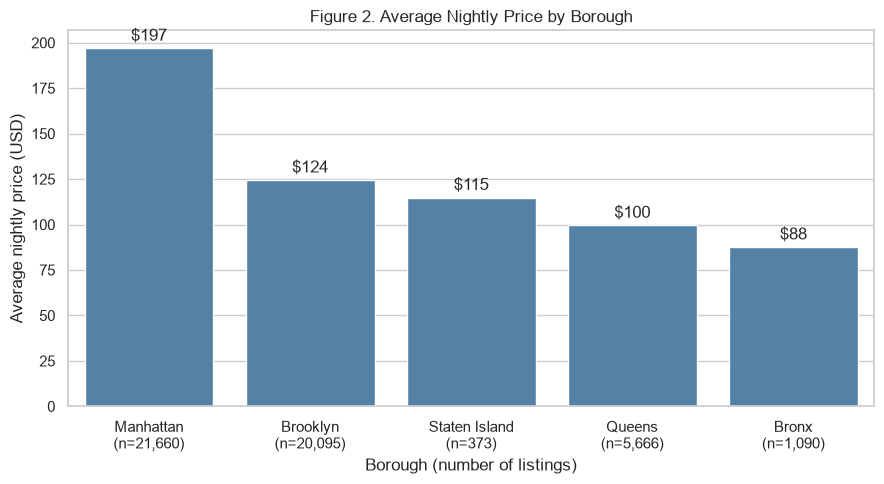

In [10]:
borough_summary = eda_results["borough_summary"]
labels = [f"{borough}\n(n={count:,})" for borough, count in borough_summary["listings"].items()]

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=labels, y=borough_summary["average_price"].to_numpy(), color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], fmt="$%.0f", padding=3)
ax.set_title("Figure 2. Average Nightly Price by Borough")
ax.set_xlabel("Borough (number of listings)")
ax.set_ylabel("Average nightly price (USD)")
fig.tight_layout()
plt.savefig("outputs/nyc_airbnb_average_price_by_borough.png")
plt.show()

### Figure 3: Price by room type

Box plots compare the median, spread, and overlap of prices for the three room types, which a single average per group would hide.

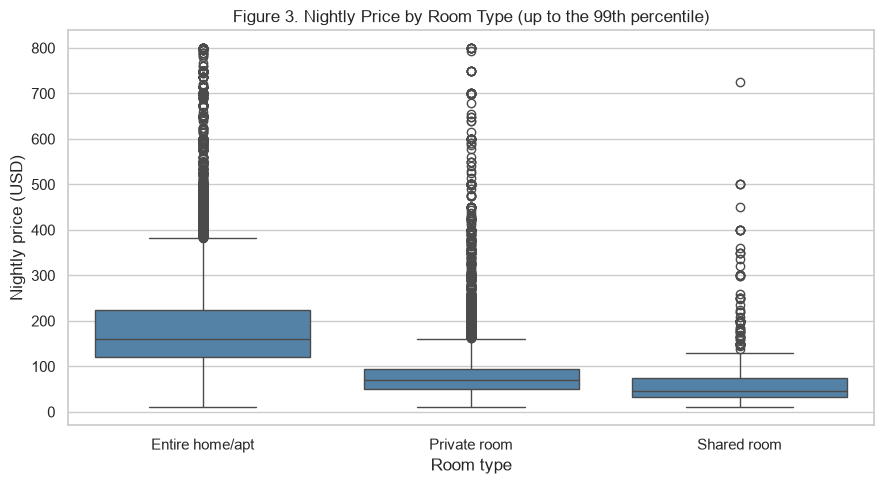

In [11]:
room_order = eda_results["room_type_summary"].index.tolist()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=plot_df, x="room_type", y="price", order=room_order, color="steelblue", ax=ax)
ax.set_title("Figure 3. Nightly Price by Room Type (up to the 99th percentile)")
ax.set_xlabel("Room type")
ax.set_ylabel("Nightly price (USD)")
fig.tight_layout()
plt.savefig("outputs/nyc_airbnb_price_by_room_type.png")
plt.show()

## 6. Summary and Interpretation

**What I learned.** The dataset contains 48,895 Airbnb listings from New York City in 2019, described by 16 columns covering location, room type, price, availability, and review activity. Cleaning removed only 11 listings with a price of zero, so 48,884 listings remain, but it also showed that missing review values are not random: all 10,052 listings with a missing review rate have zero reviews. The workflow now loads, audits, cleans, summarizes, and visualizes the data through reusable functions, which makes it a suitable foundation for later modeling work.

**Interesting patterns.** Nightly prices are strongly right-skewed: the mean price is $153 while the median is $106, and the most expensive listing costs $10,000 (Figure 1). Manhattan has the highest average price at $197 and the Bronx has the lowest at $88, while Manhattan and Brooklyn together account for 85% of all listings (Figure 2). Entire homes and apartments have a median price of $160, compared with $70 for private rooms and $45 for shared rooms, although some private rooms cost more than the median entire home (Figure 3). Among neighbourhoods with at least 100 listings, Tribeca has the highest median price at $295. Price has only weak linear relationships with the other numeric columns, with correlations between -0.05 and 0.08, so no single column in this table explains it well.

**Assumptions and limitations.** I assumed that each `id` is one unique listing, that a price of zero is invalid rather than a free listing, and that a missing review rate means zero reviews per month only when the listing has no reviews. Extreme prices and minimum stays were kept in the data because the file does not show that they are errors, and the 474 listings above the 99th percentile of price are left out only from the drawings in Figures 1 and 3. The data is a 2019 snapshot of advertised prices rather than prices actually paid, so it may not describe the current market. Staten Island (373 listings) and the Bronx (1,090 listings) have much smaller samples than Manhattan and Brooklyn, so their averages are less stable. The correlations describe linear association only and do not show what causes price differences.

**Surprising or unclear.** It is surprising that 36% of listings show zero available days in the next year, and the dataset does not explain whether these listings are fully booked, blocked by the host, or inactive. It is also unclear why 747 listings require a minimum stay of more than 30 days, including 14 that require more than a year, since these may be data-entry mistakes or long-term rentals. Staten Island has the highest average availability (200 days) despite a lower price than Manhattan, but with so few listings I cannot tell whether this reflects real demand or the small sample.